# RAID-KL + VanillaKD — SSL-CL-DNN Teacher (v1 fixed τ | v2 adaptive τ | v3 VanillaKD)

Train **3 student SSL-CL-DNN song song theo epoch** (1 vòng lặp, chung teacher + data).

**Cập nhật lần này:**
- **Student chia 4 chiều rộng** + cắt 1 layer encoder:
  - Encoder: `37→128→64→64` (3 Linear).
  - Classifier: `64→32→8`.
- **Class weight** từ `class_weights_p3.json` (đặt cạnh dataset), **clip max=3**, chỉ áp vào CE với nhãn thật.
- **Optimizer: AdamW, weight_decay = 0.01** (cố định cho SSL).

**3 phương pháp (giữ nguyên hyperparameter):**
- v1 RAID-KL fixed τ=7 | v2 RAID-KL adaptive τ∈[2,7] | v3 VanillaKD (T=3, α=0.5). α=0.5, λ=0.3.

Lưu 3 `.pth` state_dict, checkpoint độc lập, model size `count_params()×4/1024²`, plots lưới 3×3.


## Cell 1 — Cấu hình & Import

In [1]:
!pip install -q pyarrow pandas scikit-learn torch matplotlib seaborn

import os, gc, time, glob, warnings, json, tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import (
    classification_report, roc_auc_score,
    accuracy_score, confusion_matrix, f1_score
)

warnings.filterwarnings('ignore')

# ── Duong dan ────────────────────────────────────────────────────────────────
INPUT_DIR    = '/kaggle/input/datasets/rsnngo/37ft-thang3737'
TEACHER_PTH  = '/kaggle/input/datasets/rsnngo/teacher-model-thang3737/teacher_ssl_cl_dnn_after_optuna_37ft.pth'
OUTPUT_DIR   = '/kaggle/working/'
TRAIN_FILE   = os.path.join(INPUT_DIR, 'train_standard_p3.2.parquet')
VAL_FILE     = os.path.join(INPUT_DIR, 'val_standard_p3.2.parquet')
TEST_FILE    = os.path.join(INPUT_DIR, 'test_standard_p3.2.parquet')
CLASS_WEIGHTS_JSON = os.path.join(INPUT_DIR, 'class_weights_p3.2.json')   # canh dataset

V1_PATH      = os.path.join(OUTPUT_DIR, 'student_ssl_cl_dnn_fix_t_classw3_37ft.pth')
V2_PATH      = os.path.join(OUTPUT_DIR, 'student_ssl_cl_dnn_adapt_t_classw3_37ft.pth')
V3_PATH      = os.path.join(OUTPUT_DIR, 'student_ssl_cl_dnn_vanilla_kd_classw3_37ft.pth')
V1_CKPT_DIR  = os.path.join(OUTPUT_DIR, 'ckpt_v1')
V2_CKPT_DIR  = os.path.join(OUTPUT_DIR, 'ckpt_v2')
V3_CKPT_DIR  = os.path.join(OUTPUT_DIR, 'ckpt_v3')
for d in [OUTPUT_DIR, V1_CKPT_DIR, V2_CKPT_DIR, V3_CKPT_DIR]:
    os.makedirs(d, exist_ok=True)

# ── Hang so model ─────────────────────────────────────────────────────────────
NUM_FEATURES      = 37
NUM_CLASSES       = 8
LABEL_COL         = 'label'
TEACHER_EMBED_DIM = 256                 # encoder teacher output
STUDENT_EMBED_DIM = 64                  # encoder student output (chia 4)
LABEL_NAMES = {0:'Benign',1:'DDoS',2:'DoS',3:'BruteForce',
               4:'Spoofing',5:'Recon',6:'Web-Based',7:'Mirai'}
CLASS_NAMES = [LABEL_NAMES[i] for i in range(NUM_CLASSES)]
COLORS = ['#4C9BE8','#E84C4C','#F5A623','#9B59B6',
          '#2ECC71','#1ABC9C','#8B4513','#607D8B']

# ── Hyperparameters training (SSL: giu nguyen tu ban goc) ────────────────────
BATCH_SIZE       = 128
N_EPOCHS         = 50
LR               = 0.0001487
WEIGHT_DECAY     = 0.01        # SSL: co dinh 0.01 (AdamW)
CHECKPOINT_EVERY = 5
RANDOM_SEED      = 42
CLASS_WEIGHT_MAX = 3.0         # clip max cho class weight

# ── RAID-KL / VanillaKD hyperparams (giu nguyen) ─────────────────────────────
ALPHA   = 0.5
LAMBDA  = 0.3
TAU_FIXED = 7.0
TAU_MIN   = 2.0
TAU_MAX   = 7.0
VKD_ALPHA = 0.5
VKD_T     = 3

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('=' * 64)
print('  RAID-KL + VanillaKD -- SSL-CL-DNN (student chia 4 + class weight)')
print('=' * 64)
print(f'  Device     : {DEVICE}')
print(f'  Batch/LR/WD: {BATCH_SIZE} / {LR} / {WEIGHT_DECAY} (AdamW)')
print(f'  Encoder    : 37->128->64->64  |  Classifier: 64->32->8')
print(f'  α={ALPHA} λ={LAMBDA} | v1 τ={TAU_FIXED} | v2 τ∈[{TAU_MIN},{TAU_MAX}] | VKD T={VKD_T} α={VKD_ALPHA}')
print(f'  Class weight: {CLASS_WEIGHTS_JSON} (clip max={CLASS_WEIGHT_MAX}, chi vao CE)')
print('=' * 64)


  RAID-KL + VanillaKD -- SSL-CL-DNN (student chia 4 + class weight)
  Device     : cuda
  Batch/LR/WD: 128 / 0.0001487 / 0.01 (AdamW)
  Encoder    : 37->128->64->64  |  Classifier: 64->32->8
  α=0.5 λ=0.3 | v1 τ=7.0 | v2 τ∈[2.0,7.0] | VKD T=3 α=0.5
  Class weight: /kaggle/input/datasets/rsnngo/37ft-thang3737/class_weights_p3.2.json (clip max=3.0, chi vao CE)


## Cell 2 — Load class weights (từ JSON, clip max=3)

In [2]:
def load_class_weights(json_path, num_classes=NUM_CLASSES, clip_max=CLASS_WEIGHT_MAX):
    """Doc class_weights_p3.json (canh dataset), lay 'weights_balanced', clip max.
    File thuc te co dang:
      {"train_counts_label8": [...], "weights_balanced": [w0..w7], "usage": "..."}
    Ho tro linh hoat:
      - dict co key 'weights_balanced' (dang chinh) -> lay list do
      - dict co key 'class_weights'/'weights' -> lay
      - list phang [w0..w7] -> dung thang
      - dict {"0": w0,...} hoac {"Benign": w0,...} -> map theo index/ten
    """
    with open(json_path, 'r') as f:
        raw = json.load(f)

    weights = np.ones(num_classes, dtype=np.float32)

    # Uu tien lay 'weights_balanced' (hoac cac key tuong duong) neu la dict bao ngoai
    if isinstance(raw, dict) and any(k in raw for k in ('weights_balanced', 'class_weights', 'weights')):
        for key in ('weights_balanced', 'class_weights', 'weights'):
            if key in raw:
                arr = raw[key]
                assert len(arr) == num_classes, f'{key} len {len(arr)} != {num_classes}'
                weights = np.array(arr, dtype=np.float32)
                print(f'  Lay class weight tu key "{key}"')
                break
    elif isinstance(raw, list):
        assert len(raw) == num_classes, f'JSON list len {len(raw)} != {num_classes}'
        weights = np.array(raw, dtype=np.float32)
    elif isinstance(raw, dict):
        # dict map truc tiep index/ten -> weight
        name_to_idx = {v: k for k, v in LABEL_NAMES.items()}
        for k, val in raw.items():
            if str(k).isdigit():
                idx = int(k)
            elif k in name_to_idx:
                idx = name_to_idx[k]
            else:
                raise ValueError(f'Key JSON khong nhan dang: {k}')
            weights[idx] = float(val)
    else:
        raise ValueError('Dinh dang class_weights JSON khong ho tro')

    # Clip max (vd 69.7, 36.8 -> 3.0)
    weights_clipped = np.minimum(weights, clip_max)
    return torch.tensor(weights_clipped, dtype=torch.float32, device=DEVICE), weights


try:
    class_weights, class_weights_raw = load_class_weights(CLASS_WEIGHTS_JSON)
    print(f'Class weights (balanced -> clip max={CLASS_WEIGHT_MAX:.1f}):')
    for i in range(NUM_CLASSES):
        clipped = ' <- CLIP' if class_weights_raw[i] > CLASS_WEIGHT_MAX else ''
        print(f'  [{i}] {LABEL_NAMES[i]:12s}: {class_weights_raw[i]:8.4f} -> {class_weights[i].item():.4f}{clipped}')
except FileNotFoundError:
    print(f'CANH BAO: khong tim thay {CLASS_WEIGHTS_JSON}')
    print('  -> class_weights = None (khong ap dung class weight).')
    class_weights = None


  Lay class weight tu key "weights_balanced"
Class weights (balanced -> clip max=3.0):
  [0] Benign      :   0.8334 -> 0.8334
  [1] DDoS        :   0.2914 -> 0.2914
  [2] DoS         :   0.9012 -> 0.9012
  [3] BruteForce  :  69.7046 -> 3.0000 <- CLIP
  [4] Spoofing    :   2.0023 -> 2.0023
  [5] Recon       :   1.4567 -> 1.4567
  [6] Web-Based   :  36.8116 -> 3.0000 <- CLIP
  [7] Mirai       :   0.9697 -> 0.9697


## Cell 3 — Dataset

In [3]:
class ParquetDataset(Dataset):
    def __init__(self, path, label_col=LABEL_COL):
        df = pd.read_parquet(path)
        feat_cols = [c for c in df.columns if c != label_col]
        assert len(feat_cols) == NUM_FEATURES, f'{len(feat_cols)} != {NUM_FEATURES}'
        self.X = torch.from_numpy(df[feat_cols].to_numpy(dtype=np.float32))
        self.y = torch.from_numpy(df[label_col].to_numpy(dtype=np.int64))
        print(f'  {path.split("/")[-1]}: {len(self.X):,} mau')
    def __len__(self):        return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]

print('Dang doc du lieu ...')
train_ds = ParquetDataset(TRAIN_FILE)
val_ds   = ParquetDataset(VAL_FILE)
test_ds  = ParquetDataset(TEST_FILE)

kw = dict(batch_size=BATCH_SIZE, num_workers=2, pin_memory=True)
train_loader = DataLoader(train_ds, shuffle=True,  **kw)
val_loader   = DataLoader(val_ds,   shuffle=False, **kw)
test_loader  = DataLoader(test_ds,  shuffle=False, **kw)
print(f'Dataset san sang | train {len(train_loader):,} batches')


Dang doc du lieu ...
  train_standard_p3.2.parquet: 4,468,344 mau
  val_standard_p3.2.parquet: 1,117,087 mau
  test_standard_p3.2.parquet: 1,396,358 mau
Dataset san sang | train 34,909 batches


## Cell 4 — Kiến trúc Teacher & 3 Student (student chia 2)

- Teacher: Encoder `37→512→512→256→256` + ClassificationHead `256→256→8` (load `.pth`).
- Student encoder MiniDNNEncoder `37→128→64→64`; classifier `64→32→8`.
- v1/v3 không proj; v2 có `proj(64→256)` cho adaptive τ (feat_t = encoder teacher 256-dim).


In [4]:
# ── Teacher ───────────────────────────────────────────────────────────────────
class DNNEncoder(nn.Module):
    def __init__(self, in_dim=NUM_FEATURES, embedding_dim=TEACHER_EMBED_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 512), nn.ReLU(),
            nn.Linear(512, 512),    nn.ReLU(),
            nn.Linear(512, 256),    nn.ReLU(),
            nn.Linear(256, embedding_dim), nn.ReLU())
    def forward(self, x): return self.net(x)

class ProjectionHead(nn.Module):
    def __init__(self, in_dim=256, hidden_dim=256, out_dim=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim,hidden_dim), nn.ReLU(),
                                 nn.Linear(hidden_dim,out_dim))
    def forward(self, x): return self.net(x)

class ClassificationHead(nn.Module):
    def __init__(self, in_dim=256, hidden_dim=256, num_classes=NUM_CLASSES, dropout_rate=0.1):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim,hidden_dim), nn.ReLU(),
                                 nn.Dropout(dropout_rate), nn.Linear(hidden_dim,num_classes))
    def forward(self, x): return self.net(x)


# ── Student MOI (chia 2 + cat 1 layer) ───────────────────────────────────────
class MiniDNNEncoder(nn.Module):
    """37 -> 128 -> 64 -> 64 (chia 4 width)."""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(NUM_FEATURES, 128), nn.ReLU(),
            nn.Linear(128, 64),           nn.ReLU(),
            nn.Linear(64, STUDENT_EMBED_DIM), nn.ReLU())
    def forward(self, x): return self.net(x)
    def forward_hint(self, x, guided_idx=3):
        """guided = ReLU giua (idx 3, sau Linear(256,128)) -> 128-dim."""
        guided = None; h = x
        for i, layer in enumerate(self.net):
            h = layer(h)
            if i == guided_idx: guided = h
        return h, guided

class MiniClassifier(nn.Module):
    """64 -> 32 -> 8."""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(STUDENT_EMBED_DIM, 32), nn.ReLU(),
                                 nn.Linear(32, NUM_CLASSES))
    def forward(self, x): return self.net(x)


# ── 3 student ─────────────────────────────────────────────────────────────────
class StudentV1(nn.Module):
    def __init__(self):
        super().__init__(); self.encoder = MiniDNNEncoder(); self.classifier = MiniClassifier()
    def forward(self, x): return self.classifier(self.encoder(x))

class StudentV2(nn.Module):
    def __init__(self):
        super().__init__(); self.encoder = MiniDNNEncoder(); self.classifier = MiniClassifier()
        self.proj = nn.Linear(STUDENT_EMBED_DIM, TEACHER_EMBED_DIM, bias=False)  # 64->256
    def forward(self, x):
        feat      = self.encoder(x)            # [B,128]
        logits    = self.classifier(feat)
        feat_proj = self.proj(feat)            # [B,256]
        return logits, feat_proj

class StudentV3(nn.Module):
    def __init__(self):
        super().__init__(); self.encoder = MiniDNNEncoder(); self.classifier = MiniClassifier()
    def forward(self, x): return self.classifier(self.encoder(x))


def count_params(m): return sum(p.numel() for p in m.parameters())

_t = count_params(DNNEncoder()) + count_params(ClassificationHead())
for nm, cls in [('v1',StudentV1),('v2',StudentV2),('v3',StudentV3)]:
    sp = count_params(cls())
    print(f'Student {nm}: {sp:,}  compression {1-sp/_t:.1%}')
print(f'Teacher: {_t:,}')
print('Kien truc san sang')


Student v1: 19,624  compression 96.4%
Student v2: 36,008  compression 93.4%
Student v3: 19,624  compression 96.4%
Teacher: 547,080
Kien truc san sang


## Cell 5 — Loss Functions (class weight chỉ vào CE)

In [5]:
def js_divergence(p, q):
    m     = 0.5 * (p + q)
    kl_pm = F.kl_div((m + 1e-8).log(), p + 1e-8, reduction='batchmean')
    kl_qm = F.kl_div((m + 1e-8).log(), q + 1e-8, reduction='batchmean')
    return 0.5 * kl_pm + 0.5 * kl_qm

def ce_weighted(logits, labels):
    """CE co class weight (chi ap vao nhan that)."""
    return F.cross_entropy(logits, labels, weight=class_weights)

def raid_kl_loss_v1(logits_s, logits_t, labels):
    tau = TAU_FIXED
    p_t = F.softmax(logits_t / tau, dim=-1)
    p_s = F.softmax(logits_s / tau, dim=-1)
    kl  = F.kl_div((p_s + 1e-8).log(), p_t + 1e-8, reduction='batchmean')
    js  = js_divergence(p_t, p_s)
    L_ce = ce_weighted(logits_s, labels)
    return (1.0 - LAMBDA) * L_ce + LAMBDA * (tau ** 2) * (ALPHA * kl + (1.0 - ALPHA) * js)

def adaptive_temperature(feat_t, feat_s_proj):
    ft = F.normalize(feat_t,      dim=-1)
    fs = F.normalize(feat_s_proj, dim=-1)
    cos_sim = (ft * fs).sum(dim=-1).mean()
    return (TAU_MIN + (TAU_MAX - TAU_MIN) * (1.0 - cos_sim)).clamp(TAU_MIN, TAU_MAX)

def raid_kl_loss_v2(logits_s, logits_t, feat_t, feat_s_proj, labels):
    tau = adaptive_temperature(feat_t, feat_s_proj)
    p_t = F.softmax(logits_t / tau, dim=-1)
    p_s = F.softmax(logits_s / tau, dim=-1)
    kl  = F.kl_div((p_s + 1e-8).log(), p_t + 1e-8, reduction='batchmean')
    js  = js_divergence(p_t, p_s)
    L_ce = ce_weighted(logits_s, labels)
    return (1.0 - LAMBDA) * L_ce + LAMBDA * (tau ** 2) * (ALPHA * kl + (1.0 - ALPHA) * js)

def vanilla_kd_loss(logits_s, logits_t, labels):
    p_t     = F.softmax(logits_t / VKD_T, dim=-1)
    log_p_s = F.log_softmax(logits_s / VKD_T, dim=-1)
    L_distill = F.kl_div(log_p_s, p_t, reduction='batchmean') * (VKD_T ** 2)
    L_ce      = ce_weighted(logits_s, labels)
    return VKD_ALPHA * L_distill + (1.0 - VKD_ALPHA) * L_ce

print('Loss functions san sang (class weight chi vao CE, KHONG vao KL/JS/distill)')


Loss functions san sang (class weight chi vao CE, KHONG vao KL/JS/distill)


## Cell 6 — Load Teacher (.pth, frozen)

In [6]:
print('Load teacher SSL-CL-DNN (.pth) ...')
ckpt = torch.load(TEACHER_PTH, map_location='cpu', weights_only=False)
t_encoder = DNNEncoder().eval(); t_cls = ClassificationHead().eval()
t_encoder.load_state_dict(ckpt['encoder_state_dict'])
t_cls.load_state_dict(ckpt['classifier_state_dict'])
t_encoder.to(DEVICE); t_cls.to(DEVICE)
for p in t_encoder.parameters(): p.requires_grad = False
for p in t_cls.parameters():     p.requires_grad = False
t_params = count_params(t_encoder) + count_params(t_cls)

@torch.no_grad()
def teacher_forward(x):
    """Tra (logits_t, feat_t) -- feat_t = encoder output 256-dim (cho adaptive τ)."""
    feat = t_encoder(x)
    return t_cls(feat), feat

_x = train_ds.X[:4].to(DEVICE)
_l, _f = teacher_forward(_x)
print(f'Teacher params: {t_params:,} | feat dim {_f.shape[1]} (ky vong {TEACHER_EMBED_DIM})')
assert _f.shape[1] == TEACHER_EMBED_DIM
del _x, _l, _f


Load teacher SSL-CL-DNN (.pth) ...
Teacher params: 547,080 | feat dim 256 (ky vong 256)


## Cell 7 — Khởi tạo 3 Student & Optimizer (AdamW wd=0.01, auto-resume)

In [7]:
def find_latest_ckpt(ckpt_dir):
    files = sorted(glob.glob(os.path.join(ckpt_dir, 'ckpt_student_epoch_*.pth')))
    return files[-1] if files else None

def init_student(model_cls, ckpt_dir, version):
    student   = model_cls().to(DEVICE)
    optimizer = optim.AdamW(student.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    start_epoch = 1
    train_losses, val_losses = [], []
    best_val_loss = float('inf'); best_state = None
    latest = find_latest_ckpt(ckpt_dir)
    if latest:
        ck = torch.load(latest, map_location='cpu')
        student.load_state_dict(ck['model_state']); student.to(DEVICE)
        start_epoch   = ck['epoch'] + 1
        train_losses  = ck.get('train_losses', [])
        val_losses    = ck.get('val_losses',   [])
        best_val_loss = ck.get('best_val_loss', float('inf'))
        best_state    = {k: v.clone() for k, v in student.state_dict().items()}
        print(f'  [{version}] Resume: {os.path.basename(latest)} (epoch {start_epoch})')
    else:
        print(f'  [{version}] Train tu dau')
    return student, optimizer, start_epoch, train_losses, val_losses, best_val_loss, best_state

(student_v1, opt_v1, start_v1, tl_v1, vl_v1, bvl_v1, bs_v1) = init_student(StudentV1, V1_CKPT_DIR, 'v1')
(student_v2, opt_v2, start_v2, tl_v2, vl_v2, bvl_v2, bs_v2) = init_student(StudentV2, V2_CKPT_DIR, 'v2')
(student_v3, opt_v3, start_v3, tl_v3, vl_v3, bvl_v3, bs_v3) = init_student(StudentV3, V3_CKPT_DIR, 'v3')

print(f'\nStudent v1/v2/v3 params: {count_params(student_v1):,} / {count_params(student_v2):,} / {count_params(student_v3):,}')
print(f'Compression (v1): {1-count_params(student_v1)/t_params:.1%}')


  [v1] Train tu dau
  [v2] Train tu dau
  [v3] Train tu dau

Student v1/v2/v3 params: 19,624 / 36,008 / 19,624
Compression (v1): 96.4%


## Cell 8 — Training Loop (3 student song song theo epoch)

In [8]:
def save_ckpt(ckpt_dir, epoch, best_state, tl, vl, bvl):
    path = os.path.join(ckpt_dir, f'ckpt_student_epoch_{epoch:04d}.pth')
    torch.save({'epoch': epoch, 'model_state': best_state,
                'train_losses': tl, 'val_losses': vl, 'best_val_loss': bvl}, path)
    return path

start_epoch = min(start_v1, start_v2, start_v3)

if start_v1 > N_EPOCHS and start_v2 > N_EPOCHS and start_v3 > N_EPOCHS:
    print('Ca 3 student da train xong. Load best state.')
    student_v1.load_state_dict(bs_v1); student_v2.load_state_dict(bs_v2); student_v3.load_state_dict(bs_v3)
    student_v1.to(DEVICE); student_v2.to(DEVICE); student_v3.to(DEVICE)
else:
    t_encoder.eval(); t_cls.eval()
    print(f'[KD] Train tu epoch {start_epoch}/{N_EPOCHS}')
    print(f'{"Epoch":>6} | {"v1 Tr":>8} {"v1 Vl":>8} | {"v2 Tr":>8} {"v2 Vl":>8} | {"v3 Tr":>8} {"v3 Vl":>8} | {"LR":>9}')
    print('-' * 88)
    t0 = time.time()

    for epoch in range(start_epoch, N_EPOCHS + 1):
        student_v1.train(); student_v2.train(); student_v3.train()
        r1 = r2 = r3 = 0.0; n_seen = 0
        for Xb, yb in train_loader:
            Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
            logits_t, feat_t = teacher_forward(Xb)
            if epoch >= start_v1:
                loss1 = raid_kl_loss_v1(student_v1(Xb), logits_t, yb)
                opt_v1.zero_grad(); loss1.backward(); opt_v1.step(); r1 += loss1.item()*len(yb)
            if epoch >= start_v2:
                ls2, fp = student_v2(Xb)
                loss2 = raid_kl_loss_v2(ls2, logits_t, feat_t, fp, yb)
                opt_v2.zero_grad(); loss2.backward(); opt_v2.step(); r2 += loss2.item()*len(yb)
            if epoch >= start_v3:
                loss3 = vanilla_kd_loss(student_v3(Xb), logits_t, yb)
                opt_v3.zero_grad(); loss3.backward(); opt_v3.step(); r3 += loss3.item()*len(yb)
            n_seen += len(yb)
        t1v=r1/max(n_seen,1); t2v=r2/max(n_seen,1); t3v=r3/max(n_seen,1)
        tl_v1.append(t1v); tl_v2.append(t2v); tl_v3.append(t3v)

        student_v1.eval(); student_v2.eval(); student_v3.eval()
        vr1=vr2=vr3=0.0; v_seen=0
        with torch.no_grad():
            for Xb, yb in val_loader:
                Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
                logits_t, feat_t = teacher_forward(Xb)
                if epoch >= start_v1: vr1 += raid_kl_loss_v1(student_v1(Xb), logits_t, yb).item()*len(yb)
                if epoch >= start_v2:
                    ls2, fp = student_v2(Xb); vr2 += raid_kl_loss_v2(ls2, logits_t, feat_t, fp, yb).item()*len(yb)
                if epoch >= start_v3: vr3 += vanilla_kd_loss(student_v3(Xb), logits_t, yb).item()*len(yb)
                v_seen += len(yb)
        v1v=vr1/max(v_seen,1); v2v=vr2/max(v_seen,1); v3v=vr3/max(v_seen,1)
        vl_v1.append(v1v); vl_v2.append(v2v); vl_v3.append(v3v)

        cur_lr = opt_v1.param_groups[0]['lr']
        f1=f2=f3=''
        if v1v < bvl_v1: bvl_v1=v1v; bs_v1={k:v.cpu().clone() for k,v in student_v1.state_dict().items()}; f1='*'
        if v2v < bvl_v2: bvl_v2=v2v; bs_v2={k:v.cpu().clone() for k,v in student_v2.state_dict().items()}; f2='*'
        if v3v < bvl_v3: bvl_v3=v3v; bs_v3={k:v.cpu().clone() for k,v in student_v3.state_dict().items()}; f3='*'

        print(f'[{epoch:3d}/{N_EPOCHS}] | {t1v:8.4f} {v1v:7.4f}{f1:1s} | '
              f'{t2v:8.4f} {v2v:7.4f}{f2:1s} | {t3v:8.4f} {v3v:7.4f}{f3:1s} | {cur_lr:.2e}')

        if epoch % CHECKPOINT_EVERY == 0 or epoch == N_EPOCHS:
            save_ckpt(V1_CKPT_DIR, epoch, bs_v1, tl_v1, vl_v1, bvl_v1)
            save_ckpt(V2_CKPT_DIR, epoch, bs_v2, tl_v2, vl_v2, bvl_v2)
            save_ckpt(V3_CKPT_DIR, epoch, bs_v3, tl_v3, vl_v3, bvl_v3)
            print(f'  [CKPT] epoch {epoch}')
        gc.collect()

    elapsed = time.time() - t0
    student_v1.load_state_dict(bs_v1); student_v2.load_state_dict(bs_v2); student_v3.load_state_dict(bs_v3)
    student_v1.to(DEVICE); student_v2.to(DEVICE); student_v3.to(DEVICE)
    torch.save(student_v1.state_dict(), V1_PATH)
    torch.save(student_v2.state_dict(), V2_PATH)
    torch.save(student_v3.state_dict(), V3_PATH)
    print(f'\nTrain xong: {elapsed/60:.1f} phut')
    print(f'  Best val: v1={bvl_v1:.4f} v2={bvl_v2:.4f} v3={bvl_v3:.4f}')


[KD] Train tu epoch 1/50
 Epoch |    v1 Tr    v1 Vl |    v2 Tr    v2 Vl |    v3 Tr    v3 Vl |        LR
----------------------------------------------------------------------------------------
[  1/50] |   0.7937  0.5768* |   0.5739  0.4419* |   0.6474  0.4808* | 1.49e-04
[  2/50] |   0.5359  0.4946* |   0.4247  0.4093* |   0.4550  0.4289* | 1.49e-04
[  3/50] |   0.4493  0.4106* |   0.3973  0.3924* |   0.4017  0.3726* | 1.49e-04
[  4/50] |   0.3992  0.3919* |   0.3716  0.3632* |   0.3518  0.3363* | 1.49e-04
[  5/50] |   0.3822  0.3736* |   0.3522  0.3437* |   0.3224  0.3125* | 1.49e-04
  [CKPT] epoch 5
[  6/50] |   0.3719  0.3735* |   0.3404  0.3355* |   0.3066  0.2988* | 1.49e-04
[  7/50] |   0.3644  0.3624* |   0.3334  0.3326* |   0.2964  0.2958* | 1.49e-04
[  8/50] |   0.3590  0.3580* |   0.3291  0.3298* |   0.2897  0.2867* | 1.49e-04
[  9/50] |   0.3547  0.3517* |   0.3259  0.3233* |   0.2848  0.2814* | 1.49e-04
[ 10/50] |   0.3511  0.3510* |   0.3235  0.3214* |   0.2811  0.2794* |

## Cell 9 — Evaluate 3 student trên Test Set

In [9]:
def evaluate(student, version, label):
    student.eval()
    all_preds, all_probs, all_labels, latencies = [], [], [], []
    with torch.no_grad():
        _ = student(test_ds.X[:BATCH_SIZE].to(DEVICE))
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    tracemalloc.start(); gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.reset_peak_memory_stats()
    with torch.no_grad():
        for Xb, yb in test_loader:
            Xb = Xb.to(DEVICE)
            t0=time.perf_counter(); out=student(Xb); t1=time.perf_counter()
            latencies.append((t1-t0)/len(Xb))
            logits = out[0] if isinstance(out, tuple) else out
            all_probs.append(F.softmax(logits, dim=1).cpu())
            all_preds.append(logits.argmax(dim=1).cpu()); all_labels.append(yb)
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    _, ram_peak = tracemalloc.get_traced_memory(); tracemalloc.stop()

    preds  = torch.cat(all_preds).numpy(); probs = torch.cat(all_probs).numpy()
    labels = torch.cat(all_labels).numpy()
    acc = accuracy_score(labels, preds)
    macro_auc = roc_auc_score(labels, probs, multi_class='ovr', average='macro')
    report = classification_report(labels, preds, target_names=CLASS_NAMES, digits=4)
    n_params = count_params(student); size_mb = n_params*4/1024**2
    inf_us = np.mean(latencies)*1e6

    result = (
        f"\n{'='*62}\n  {label} -- TEST\n{'='*62}\n{report}\n"
        f"Accuracy         : {acc:.6f}\nMacro AUC        : {macro_auc:.6f}\n{'-'*62}\n"
        f"Model size       : {size_mb:.4f} MB  ({size_mb*1024:.2f} KB)\n"
        f"Params (student) : {n_params:,}\nParams (teacher) : {t_params:,}\n"
        f"Compression      : {1 - n_params/t_params:.1%}\n"
        f"Inference/sample : {inf_us:.2f} us\n{'='*62}\n")
    print(result)
    with open(os.path.join(OUTPUT_DIR, f'results_{version}.txt'), 'w') as f:
        f.write(result)
    return preds, labels, acc, macro_auc

preds_v1, labels_v1, acc_v1, auc_v1 = evaluate(student_v1, 'v1', 'Student v1 (fixed τ=7)')
preds_v2, labels_v2, acc_v2, auc_v2 = evaluate(student_v2, 'v2', 'Student v2 (adaptive τ∈[2,7])')
preds_v3, labels_v3, acc_v3, auc_v3 = evaluate(student_v3, 'v3', 'Student v3 (VanillaKD T=3 α=0.5)')



  Student v1 (fixed τ=7) -- TEST
              precision    recall  f1-score   support

      Benign     0.8394    0.8089    0.8239    209448
        DDoS     0.9485    0.7721    0.8512    598978
         DoS     0.5534    0.8682    0.6759    193688
  BruteForce     0.6941    0.2935    0.4126      2504
    Spoofing     0.8318    0.8417    0.8367     87173
       Recon     0.7070    0.7820    0.7426    119826
   Web-Based     0.4878    0.1346    0.2109      4741
       Mirai     0.9971    0.9969    0.9970    180000

    accuracy                         0.8221   1396358
   macro avg     0.7574    0.6872    0.6939   1396358
weighted avg     0.8535    0.8221    0.8284   1396358

Accuracy         : 0.822082
Macro AUC        : 0.977471
--------------------------------------------------------------
Model size       : 0.0749 MB  (76.66 KB)
Params (student) : 19,624
Params (teacher) : 547,080
Compression      : 96.4%
Inference/sample : 10.11 us


  Student v2 (adaptive τ∈[2,7]) -- TEST
       

## Cell 10 — Plots lưới 3×3

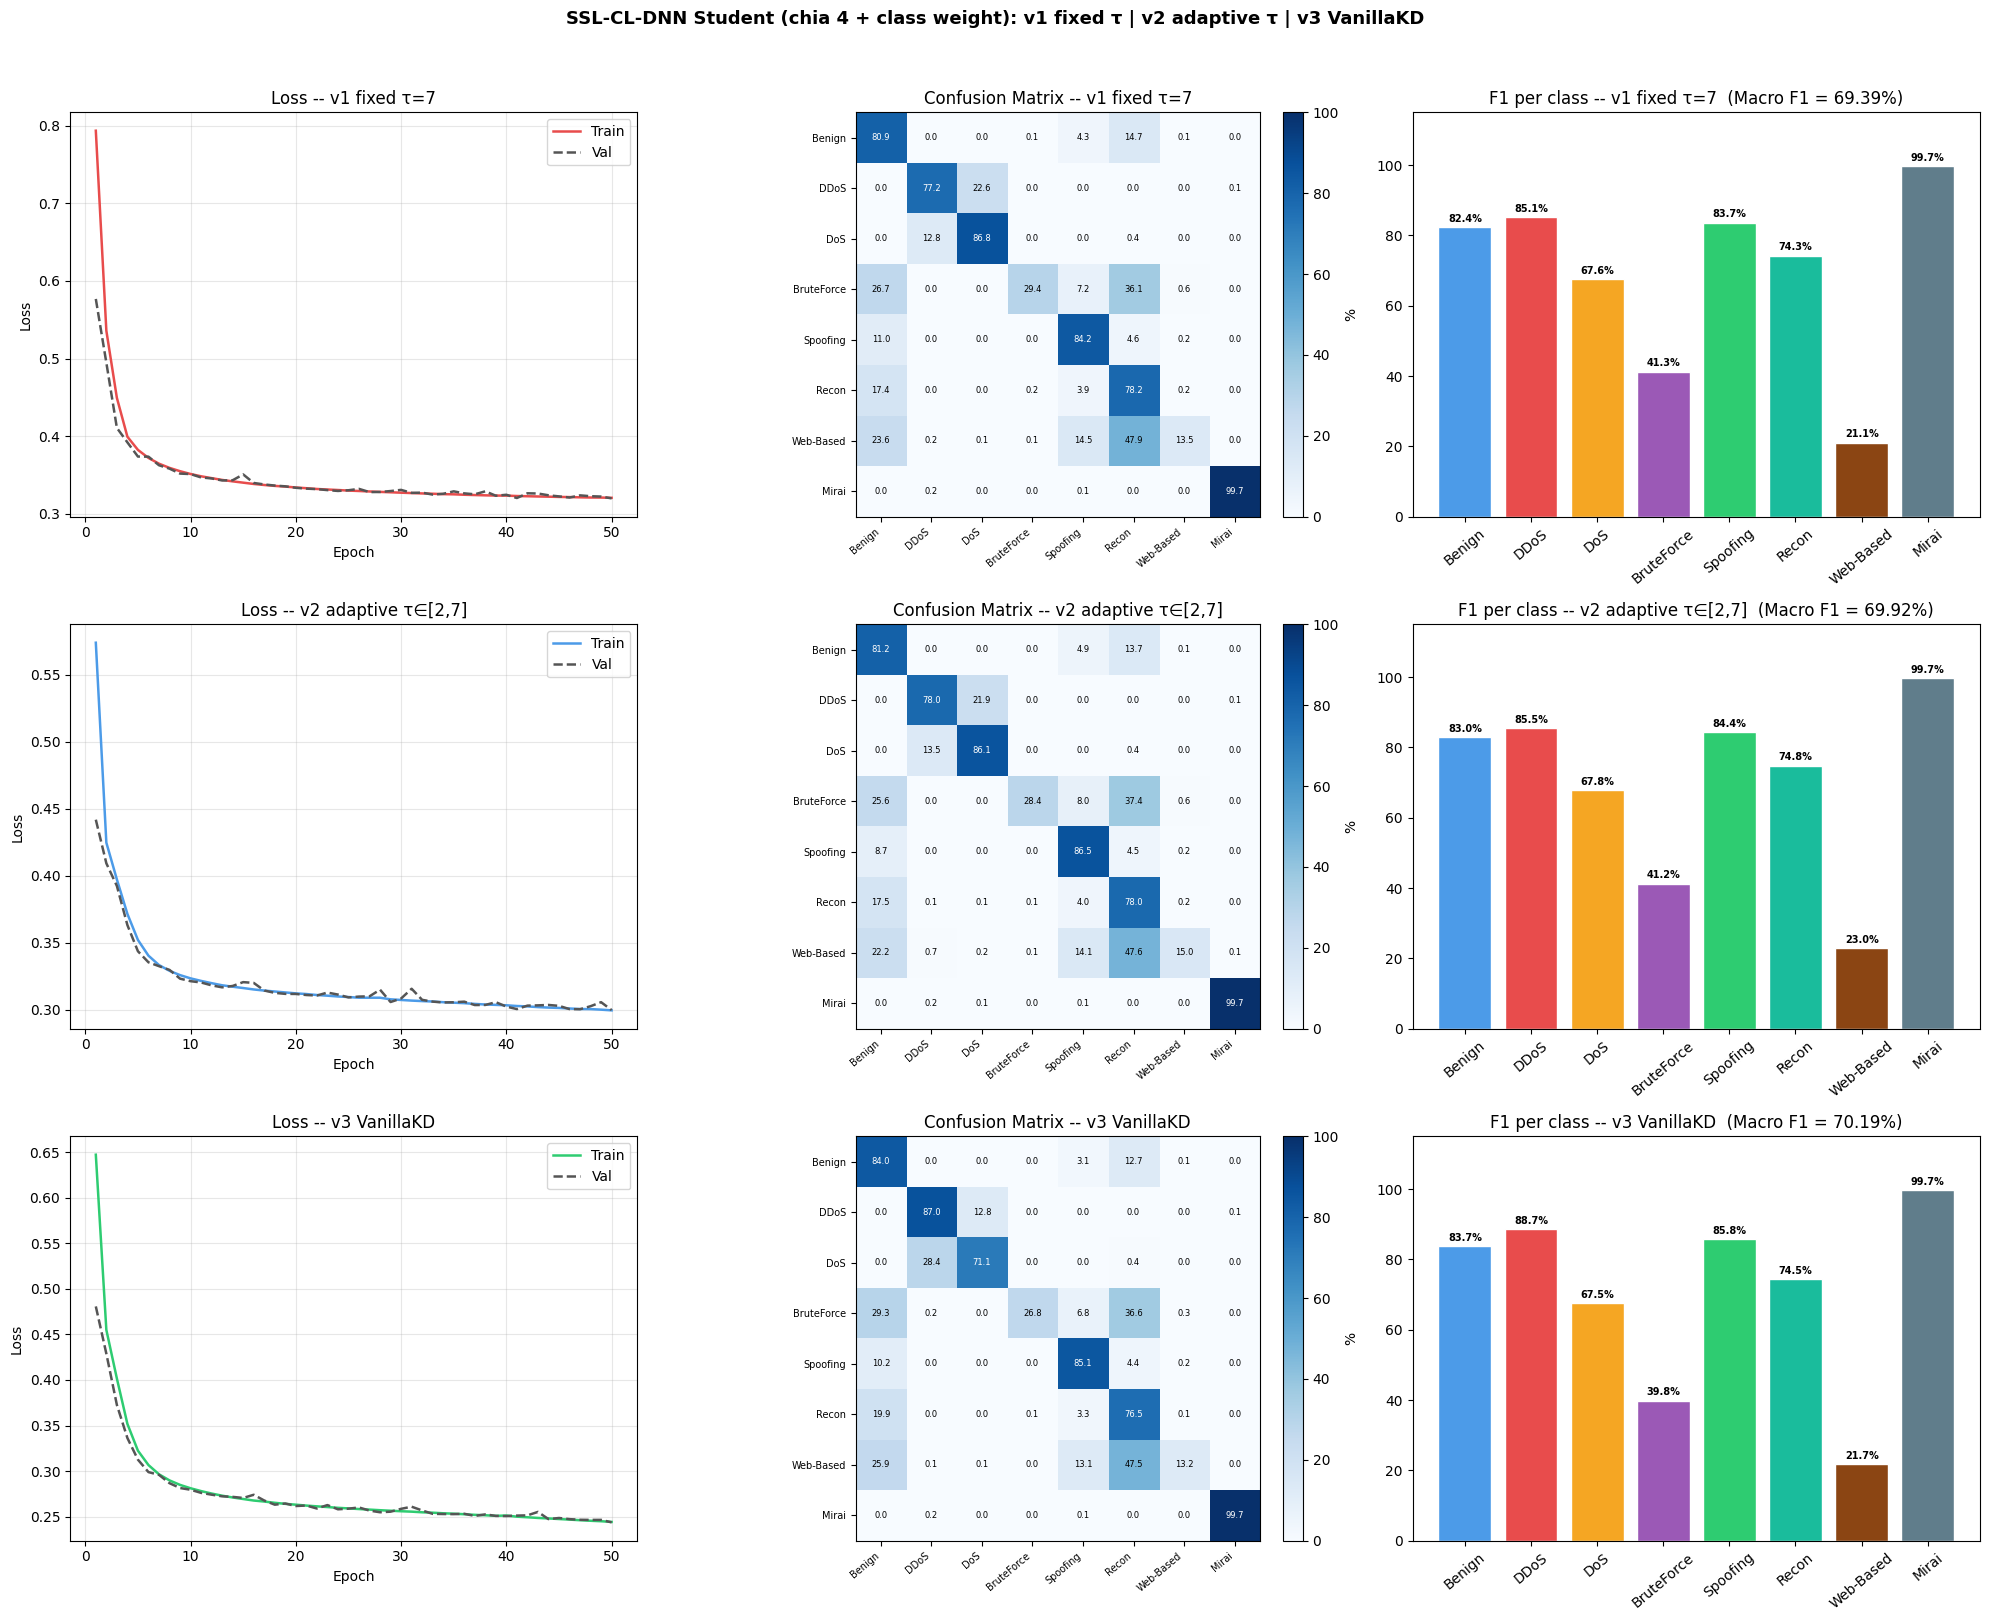

Plot -> /kaggle/working/compare_ssl_v1_v2_v3.png


In [10]:
fig, axes = plt.subplots(3, 3, figsize=(20, 16))
fig.suptitle('SSL-CL-DNN Student (chia 4 + class weight): v1 fixed τ | v2 adaptive τ | v3 VanillaKD',
             fontsize=13, fontweight='bold', y=1.01)

for row, (tl, vl, preds, labels, label, color) in enumerate([
    (tl_v1, vl_v1, preds_v1, labels_v1, 'v1 fixed τ=7',        '#E84C4C'),
    (tl_v2, vl_v2, preds_v2, labels_v2, 'v2 adaptive τ∈[2,7]', '#4C9BE8'),
    (tl_v3, vl_v3, preds_v3, labels_v3, 'v3 VanillaKD',        '#2ECC71'),
]):
    ep = range(1, len(tl) + 1)
    axes[row,0].plot(ep, tl, label='Train', color=color, lw=1.8)
    axes[row,0].plot(ep, vl, label='Val', color='#555555', lw=1.8, ls='--')
    axes[row,0].set_title(f'Loss -- {label}'); axes[row,0].set_xlabel('Epoch'); axes[row,0].set_ylabel('Loss')
    axes[row,0].legend(); axes[row,0].grid(alpha=0.3)

    cm = confusion_matrix(labels, preds)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
    im = axes[row,1].imshow(cm_pct, cmap='Blues', vmin=0, vmax=100)
    plt.colorbar(im, ax=axes[row,1], fraction=0.046, pad=0.04, label='%')
    axes[row,1].set_xticks(range(NUM_CLASSES)); axes[row,1].set_yticks(range(NUM_CLASSES))
    axes[row,1].set_xticklabels(CLASS_NAMES, rotation=40, ha='right', fontsize=7)
    axes[row,1].set_yticklabels(CLASS_NAMES, fontsize=7)
    axes[row,1].set_title(f'Confusion Matrix -- {label}')
    thr = cm_pct.max()/2
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            axes[row,1].text(j, i, f'{cm_pct[i,j]:.1f}', ha='center', va='center',
                             fontsize=6, color='white' if cm_pct[i,j] > thr else 'black')

    f1s = f1_score(labels, preds, average=None, zero_division=0)
    bars = axes[row,2].bar(CLASS_NAMES, f1s*100, color=COLORS, edgecolor='white')
    axes[row,2].set_ylim(0, 115)
    axes[row,2].set_title(f'F1 per class -- {label}  (Macro F1 = {np.mean(f1s)*100:.2f}%)')
    axes[row,2].tick_params(axis='x', rotation=40)
    for bar, val in zip(bars, f1s):
        axes[row,2].text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.5,
                         f'{val*100:.1f}%', ha='center', fontsize=7, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.99])
plot_path = os.path.join(OUTPUT_DIR, 'compare_ssl_v1_v2_v3.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight'); plt.show()
print(f'Plot -> {plot_path}')


## Cell 11 — Export config & tổng kết

In [11]:
class StudentInferenceOnly(nn.Module):
    def __init__(self, encoder, classifier):
        super().__init__(); self.encoder = encoder; self.classifier = classifier
    def forward(self, x): return self.classifier(self.encoder(x))

def export_config_onnx(student, version, acc, macro_auc, distill_info):
    n_params = count_params(student)
    config = {
        'model': f'KD-Student-{version}-SSL-CL-DNN', 'teacher': 'SSL-CL-DNN',
        'num_features': NUM_FEATURES, 'num_classes': NUM_CLASSES,
        'encoder': '37-128-64-64', 'classifier': '64-32-8',
        'distillation': distill_info, 'class_weight_max': CLASS_WEIGHT_MAX,
        'optimizer': 'AdamW', 'weight_decay': WEIGHT_DECAY,
        'performance': {'accuracy': round(float(acc),6), 'macro_auc': round(float(macro_auc),6),
                        'params': n_params, 'size_mb_fp32': round(n_params*4/1024**2,4),
                        'compression': round(1-n_params/t_params,4)}}
    with open(os.path.join(OUTPUT_DIR, f'config_{version}.json'), 'w') as f:
        json.dump(config, f, indent=2)
    infer = StudentInferenceOnly(student.encoder.cpu().eval(), student.classifier.cpu().eval())
    try:
        onnx_path = os.path.join(OUTPUT_DIR, f'student_ssl_{version}.onnx')
        torch.onnx.export(infer, torch.randn(1, NUM_FEATURES), onnx_path,
                          input_names=['features'], output_names=['logits'],
                          dynamic_axes={'features':{0:'batch'},'logits':{0:'batch'}}, opset_version=13)
        print(f'ONNX -> {onnx_path} ({os.path.getsize(onnx_path)/1024:.1f} KB)')
    except Exception as e:
        print(f'  ONNX ERROR: {e}')
    student.to(DEVICE)

export_config_onnx(student_v1, 'v1', acc_v1, auc_v1, {'method':'RAID-KL','alpha':ALPHA,'lambda':LAMBDA,'tau':TAU_FIXED,'tau_mode':'fixed'})
export_config_onnx(student_v2, 'v2', acc_v2, auc_v2, {'method':'RAID-KL','alpha':ALPHA,'lambda':LAMBDA,'tau_min':TAU_MIN,'tau_max':TAU_MAX,'tau_mode':'adaptive'})
export_config_onnx(student_v3, 'v3', acc_v3, auc_v3, {'method':'VanillaKD','alpha':VKD_ALPHA,'T':VKD_T})

print('\n' + '='*62)
print('  SSL-CL-DNN -- TONG KET 3 STUDENT (chia 2 + class weight)')
print('='*62)
print(f'  {"":22s}  {"v1 fixed":>12}  {"v2 adaptive":>12}  {"v3 Vanilla":>12}')
print(f'  {"Accuracy":22s}  {acc_v1*100:>11.4f}%  {acc_v2*100:>11.4f}%  {acc_v3*100:>11.4f}%')
print(f'  {"Macro AUC":22s}  {auc_v1:>12.6f}  {auc_v2:>12.6f}  {auc_v3:>12.6f}')
print(f'  {"Params":22s}  {count_params(student_v1):>12,}  {count_params(student_v2):>12,}  {count_params(student_v3):>12,}')
print('='*62)
print('\nOutput .pth:')
for fname in sorted(os.listdir(OUTPUT_DIR)):
    if fname.endswith('.pth'):
        print(f'  {fname:<45} {os.path.getsize(os.path.join(OUTPUT_DIR,fname))/1024:>8.1f} KB')


  ONNX ERROR: No module named 'onnxscript'
  ONNX ERROR: No module named 'onnxscript'
  ONNX ERROR: No module named 'onnxscript'

  SSL-CL-DNN -- TONG KET 3 STUDENT (chia 2 + class weight)
                              v1 fixed   v2 adaptive    v3 Vanilla
  Accuracy                    82.2082%      82.6174%      84.6407%
  Macro AUC                   0.977471      0.978008      0.978331
  Params                        19,624        36,008        19,624

Output .pth:
  student_ssl_cl_dnn_adapt_t_classw3_37ft.pth      146.0 KB
  student_ssl_cl_dnn_fix_t_classw3_37ft.pth         81.6 KB
  student_ssl_cl_dnn_vanilla_kd_classw3_37ft.pth     81.7 KB
